In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
import pandas as pd
import glob
import seaborn as sns

### Read 3D Data

In [2]:
data_path = "./../../../Datasets/MICCAI-Challenge-STSR2025-Task1/"
train_labeled_path = data_path + "Train-Labeled/"
train_unlabeled_path = data_path + "Train-Unlabeled/"
val_path = data_path + "Validation/"

In [3]:
img_path = train_labeled_path + "Images/"
mask_path = train_labeled_path + "Masks/"

In [4]:
os.listdir(img_path)

['STS25_Train_Labeled_0002.nii.gz',
 'STS25_Train_Labeled_0021.nii.gz',
 'STS25_Train_Labeled_0030.nii.gz',
 'STS25_Train_Labeled_0017.nii.gz',
 'STS25_Train_Labeled_0011.nii.gz',
 'STS25_Train_Labeled_0007.nii.gz',
 'STS25_Train_Labeled_0019.nii.gz',
 'STS25_Train_Labeled_0018.nii.gz',
 'STS25_Train_Labeled_0022.nii.gz',
 'STS25_Train_Labeled_0024.nii.gz',
 'STS25_Train_Labeled_0004.nii.gz',
 'STS25_Train_Labeled_0025.nii.gz',
 'STS25_Train_Labeled_0003.nii.gz',
 'STS25_Train_Labeled_0001.nii.gz',
 'STS25_Train_Labeled_0023.nii.gz',
 'STS25_Train_Labeled_0008.nii.gz',
 'STS25_Train_Labeled_0005.nii.gz',
 'STS25_Train_Labeled_0009.nii.gz',
 'STS25_Train_Labeled_0012.nii.gz',
 'STS25_Train_Labeled_0016.nii.gz',
 'STS25_Train_Labeled_0006.nii.gz',
 'STS25_Train_Labeled_0013.nii.gz',
 'STS25_Train_Labeled_0014.nii.gz',
 'STS25_Train_Labeled_0028.nii.gz',
 'STS25_Train_Labeled_0010.nii.gz',
 'STS25_Train_Labeled_0015.nii.gz',
 'STS25_Train_Labeled_0029.nii.gz',
 'STS25_Train_Labeled_0027.n

In [ ]:
ids = ["01","02","03","04","05","06","07","08","09","10","11","12","13","14","15","16","17","18","19","20","21","22","23","24","25","26","27","28","29","30"]

for id in ids:

    img1_path = img_path + f"STS25_Train_Labeled_00{id}.nii.gz"
    print("------------------")
    print(f"Checking image {id}:")
    # Read 3D image STS25_Train_Labeled_0005.nii.gz
    img1_nii = nib.load(img1_path)
    img1_data = img1_nii.get_fdata()

    slice = (img1_data.shape[2] // 2) + 50
    # print(slice)

    print( img1_data.shape, img1_data.dtype)


    # Show a middle slice along the z-axis
    # plt.imshow(img1_data[:, :, slice], cmap='gray')
    # plt.axis('off')
    # plt.show()

    mask1_path = mask_path + f"STS25_Train_Labeled_00{id}_Masks.nii.gz"

    mask1_nii = nib.load(mask1_path)
    mask1_data = mask1_nii.get_fdata()
    print( mask1_data.shape, mask1_data.dtype)
    
    print(np.unique(img1_data))
    print(np.unique(mask1_data))

    # Show a middle slice along the z-axis
    # plt.imshow(mask1_data[:, :, slice], cmap='gray')
    # plt.axis('off')
    # plt.show()

<class 'numpy.ndarray'> (266, 266, 200) float64
<class 'numpy.ndarray'> (266, 266, 200) float64
----------------
[-1000.  -999.  -998. ...  3080.  3083.  3095.]
[0. 1. 2. 4. 5. 7. 8. 9.]
<class 'numpy.ndarray'> (266, 266, 200) float64
<class 'numpy.ndarray'> (266, 266, 200) float64
----------------
[-1000.  -999.  -998. ...  3093.  3094.  3095.]
[ 0.  1.  2.  4.  7.  9. 12.]
<class 'numpy.ndarray'> (266, 266, 200) float64
<class 'numpy.ndarray'> (266, 266, 200) float64
----------------
[-1000.  -999.  -998. ...  3093.  3094.  3095.]
[0. 1. 2. 4. 5. 6. 7. 8. 9.]
<class 'numpy.ndarray'> (640, 640, 448) float64
<class 'numpy.ndarray'> (640, 640, 448) float64
----------------
[-1000.  -999.  -998. ...  6555.  6563.  6683.]
[ 0.  1.  2.  4.  5.  6.  7.  8.  9. 12.]
<class 'numpy.ndarray'> (536, 536, 440) float64
<class 'numpy.ndarray'> (536, 536, 440) float64
----------------
[-1000.  -999.  -998. ...  4058.  4069.  4074.]
[0. 1. 2. 4. 5. 6. 7. 8. 9.]
<class 'numpy.ndarray'> (536, 536, 440)

KeyboardInterrupt: 

In [ ]:
# print unique values of mask1_data


[-1000.  -999.  -998. ...  3080.  3083.  3095.]
[0. 1. 2. 4. 5. 7. 8. 9.]


In [5]:
nnUNet_baseline_path = "/home/22long.nh/Projects/STS2024/evaluation/3d/nnUNet_baseline/"
nnUNet_3d_fullres_path = nnUNet_baseline_path + "3d_fullres/metrics.csv"
nnUNet_3d_lowres_path = nnUNet_baseline_path + "3d_lowres/metrics.csv"
nnUNet_2d_path = nnUNet_baseline_path + "2d/metrics.csv"

df_3d_fullres = pd.read_csv(nnUNet_3d_fullres_path)
df_3d_lowres = pd.read_csv(nnUNet_3d_lowres_path)
df_2d = pd.read_csv(nnUNet_2d_path)

In [6]:
df_3d_fullres

,case,image_DSC,image_IoU,image_NSD,instance_DSC,instance_IoU,instance_NSD,IA
0,0026.nii.gz,0.9512,0.9070,0.9859,0.5445,0.4260,0.7190,0.3000
1,0027.nii.gz,0.9478,0.9009,0.9843,0.5177,0.4156,0.6987,0.3636
2,0028.nii.gz,0.9579,0.9193,0.9934,0.5062,0.4221,0.6470,0.5000
3,0029.nii.gz,0.9552,0.9142,0.9824,0.5594,0.4671,0.7004,0.5455
4,0030.nii.gz,0.9568,0.9171,0.9900,0.5045,0.4188,0.6315,0.4167


In [7]:
df_3d_lowres

,case,image_DSC,image_IoU,image_NSD,instance_DSC,instance_IoU,instance_NSD,IA
0,0026.nii.gz,0.9202,0.8522,0.9730,0.4498,0.3348,0.7276,0.3000
1,0027.nii.gz,0.9267,0.8635,0.9788,0.4637,0.3541,0.7427,0.2727
2,0028.nii.gz,0.9302,0.8695,0.9854,0.4284,0.3329,0.6488,0.2500
3,0029.nii.gz,0.9308,0.8706,0.9836,0.5077,0.3973,0.7479,0.2727
4,0030.nii.gz,0.9399,0.8866,0.9900,0.4282,0.3325,0.6523,0.2500


In [8]:
df_2d

,case,image_DSC,image_IoU,image_NSD,instance_DSC,instance_IoU,instance_NSD,IA
0,0026.nii.gz,0.8576,0.7508,0.9097,0.5295,0.3920,0.7766,0.3000
1,0027.nii.gz,0.8879,0.7983,0.9395,0.4945,0.3711,0.7293,0.2727
2,0028.nii.gz,0.9362,0.8801,0.9796,0.4666,0.3521,0.6559,0.3333
3,0029.nii.gz,0.9296,0.8684,0.9624,0.5756,0.4541,0.7652,0.4545
4,0030.nii.gz,0.8801,0.7858,0.9224,0.4764,0.3677,0.6534,0.2500


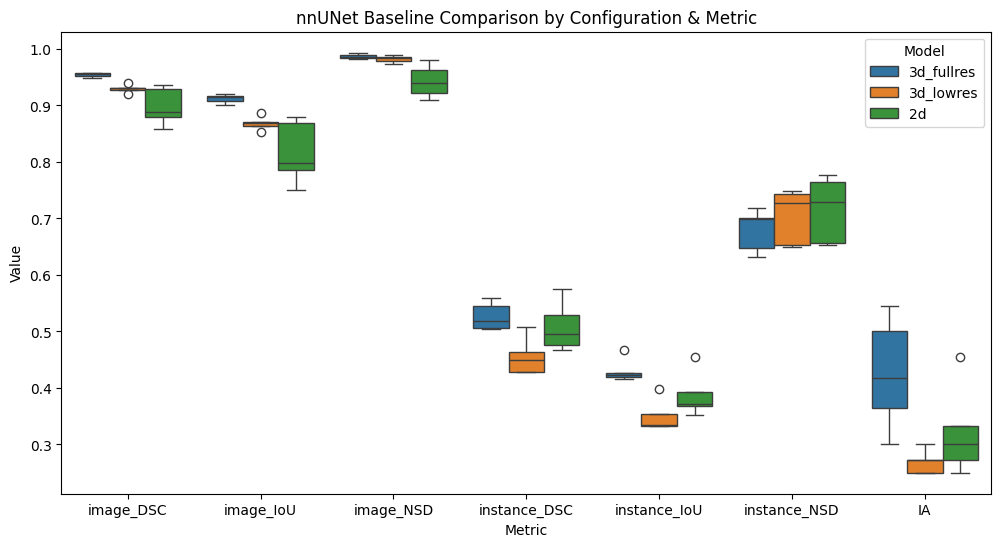

In [12]:

# Read your CSVs and add a column for model/config
# df1 = pd.read_csv('model1.csv')
df_3d_fullres['Model'] = '3d_fullres'
# df2 = pd.read_csv('model2.csv')
df_3d_lowres['Model'] = '3d_lowres'
# df3 = pd.read_csv('model3.csv')
df_2d['Model'] = '2d'

# Combine
df = pd.concat([df_3d_fullres, df_3d_lowres, df_2d], ignore_index=True)

# Select only the metric columns you want to plot
metrics = ['image_DSC', 'image_IoU', 'image_NSD', 'instance_DSC', 'instance_IoU', 'instance_NSD', 'IA']

# Melt for seaborn
df_melt = df.melt(id_vars=['Model'], value_vars=metrics, var_name='Metric', value_name='Value')

# Plot
plt.figure(figsize=(12, 6))
sns.boxplot(x='Metric', y='Value', hue='Model', data=df_melt)
plt.title('nnUNet Baseline Comparison by Configuration & Metric')
plt.show()